# 01 — Inferência e Comparação de Modelos de Profundidade

**Sidewalk Depth Research** — Ambiente Experimental

Este notebook é o entregável principal da primeira versão do projeto. Ele permite:
1. **Selecionar uma fotografia de calçada** (estática, RGB) com correção automática de orientação EXIF;
2. **Executar inferência com modelos pré-treinados**:
   - `Depth Anything V2 Small` (disparidade relativa afim-invariante);
   - `MiDaS v2.1 Small` (disparidade relativa afim-invariante);
   - `Depth Anything V2 Metric Outdoor Small` (profundidade métrica em metros);
   - `YOLO26n Depth` (profundidade métrica em metros - Ultralytics);
3. **Comparar os resultados visualmente lado a lado**:
   - Imagem RGB original;
   - Mapa de profundidade em escala de cinza (*perto = claro*);
   - Mapa colorido (*perto = claro*, com barra de cores informando os valores numéricos reais);
   - Nome do modelo, natureza da saída e tempo de inferência;
4. **Preservar os dados brutos e metadados**:
   - Arrays `float32` sem normalizações destrutivas salvos em `.npz`;
   - Metadados completos do experimento (inclusive hash SHA-256 da imagem) em `.json`;
   - Registro histórico de cada inferência em `outputs/reports/inference_log.csv`.

In [55]:
# Setup do ambiente e imports
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

# Garante que a raiz do projeto esteja no sys.path, permitindo imports de `src`
PROJECT_ROOT = Path("..").resolve() if Path(".").resolve().name == "notebooks" else Path(".").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import load_settings, get_path
from src.preprocessing import load_rgb_image, list_dataset_images
from src.inference import (
    create_estimator,
    save_depth_result,
    append_inference_log,
    available_models,
)
from src.visualization import (
    plot_comparison,
    save_depth_visualizations,
    save_figure,
)

settings = load_settings()
print(f"Projeto: {settings['project']['name']} (v{settings['project']['version']})")
print(f"Device configurado: {settings['runtime']['device']}")
print(f"Modelos habilitados: {available_models()}")

Projeto: sidewalk-depth-research (v0.1.0)
Device configurado: auto
Modelos habilitados: ['depth_anything_v2_small', 'depth_anything_v2_metric_outdoor_small', 'midas_v21_small', 'yolo26n_depth']


## 1. Seleção e Inspeção da Imagem de Entrada

O dataset armazena imagens em `datasets/images/<categoria>/`. Você pode selecionar qualquer imagem da lista ou apontar diretamente para outro arquivo sem alterar o código das classes.

Total de imagens encontradas: 4
  [0] datasets/images/uneven_surfaces/0911-1401.jpg.jpg
  [1] datasets/images/uneven_surfaces/buraco.jpg
  [2] datasets/images/uneven_surfaces/calcada-irregular-no-rio-de-janeiro.jpg
  [3] datasets/images/uneven_surfaces/images.jpeg

-> Carregando: /Users/kelvinrodrigues/Documents/projects/sidewalk_depth_research/datasets/images/uneven_surfaces/images.jpeg
Nome do arquivo:     images.jpeg
Categoria:           uneven_surfaces
Dimensões (H x W):   452 x 679 px
Modo original:       RGB
Orientação EXIF:     None (corrigida: False)


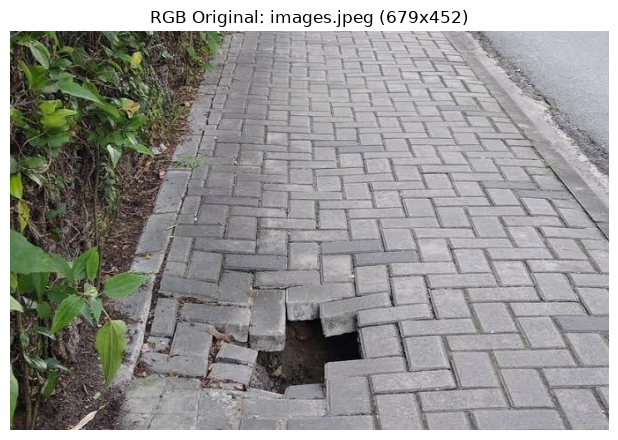

In [ ]:
# Lista todas as imagens presentes em datasets/images/
dataset_images = list_dataset_images()
print(f"Total de imagens encontradas: {len(dataset_images)}")
for idx, p in enumerate(dataset_images):
    print(f"  [{idx}] {p.relative_to(PROJECT_ROOT)}")

# Escolha o índice da imagem desejada (ou altere o caminho diretamente abaixo):
IMAGE_INDEX = 2 if len(dataset_images) > 1 else 0
SELECTED_IMAGE_PATH = dataset_images[IMAGE_INDEX] if dataset_images else "datasets/images/uneven_surfaces/images.jpeg"

print(f"\n-> Carregando: {SELECTED_IMAGE_PATH}")
image = load_rgb_image(SELECTED_IMAGE_PATH)

print(f"Nome do arquivo:     {image.name}")
print(f"Categoria:           {image.category or 'avulsa'}")
print(f"Dimensões (H x W):   {image.size_hw[0]} x {image.size_hw[1]} px")
print(f"Modo original:       {image.original_mode}")
print(f"Orientação EXIF:     {image.exif_orientation} (corrigida: {image.orientation_applied})")

# Visualização da imagem original
plt.figure(figsize=(7, 4.5))
plt.imshow(image.rgb)
plt.title(f"RGB Original: {image.name} ({image.size_hw[1]}x{image.size_hw[0]})")
plt.axis("off")
plt.tight_layout()
plt.show()

## 2. Execução dos Estimadores de Profundidade

Cada modelo possui sua própria arquitetura e fluxo de pré-processamento:
- **Depth Anything V2 Small**: DINOv2 ViT-S/14 com cabeça DPT. Produz **disparidade relativa afim-invariante** (maior valor = mais próximo).
- **MiDaS v2.1 Small**: EfficientNet-Lite3. Produz **disparidade relativa afim-invariante** (escala arbitrária, maior valor = mais próximo).
- **Depth Anything V2 Metric Outdoor Small**: DINOv2 ViT-S/14 calibrado no Virtual KITTI 2. Produz **profundidade métrica em metros** (maior valor = mais distante).
- **YOLO26n Depth**: Arquitetura Ultralytics YOLO26 Depth. Produz **profundidade métrica em metros** (otimizado para inferência rápida e exportação para edge/mobile).

> ⚠️ **Importante**: As saídas brutas são preservadas integralmente em sua escala e resolução de rede antes da interpolação para a resolução original. Nenhuma normalização destrutiva é aplicada aos dados analíticos.

In [57]:
results = []

# --- 1. Depth Anything V2 Small (Relativo) ---
print("Executando Depth Anything V2 Small...")
est_da_small = create_estimator("depth_anything_v2_small")
res_da_small = est_da_small.predict(image.rgb, warmup_runs=1)
results.append(res_da_small)
print(f"  ✓ Concluído em {res_da_small.inference_time_s * 1000:.1f} ms (inferência pura)")
print(f"    Saída: {res_da_small.output_type.value} | Shape bruto: {res_da_small.output_shape}")

# --- 2. MiDaS v2.1 Small (Relativo) ---
print("\nExecutando MiDaS v2.1 Small...")
est_midas = create_estimator("midas_v21_small")
res_midas = est_midas.predict(image.rgb, warmup_runs=1)
results.append(res_midas)
print(f"  ✓ Concluído em {res_midas.inference_time_s * 1000:.1f} ms (inferência pura)")
print(f"    Saída: {res_midas.output_type.value} | Shape bruto: {res_midas.output_shape}")

# --- 3. Depth Anything V2 Metric Outdoor Small (Métrico) ---
print("\nExecutando Depth Anything V2 Metric Outdoor Small...")
est_da_metric = create_estimator("depth_anything_v2_metric_outdoor_small")
res_da_metric = est_da_metric.predict(image.rgb, warmup_runs=1)
results.append(res_da_metric)
print(f"  ✓ Concluído em {res_da_metric.inference_time_s * 1000:.1f} ms (inferência pura)")
print(f"    Saída: {res_da_metric.output_type.value} ({res_da_metric.units}) | Shape bruto: {res_da_metric.output_shape}")

# --- 4. YOLO26n Depth (Métrico - Ultralytics) ---
print("\nExecutando YOLO26n Depth...")
est_yolo = create_estimator("yolo26n_depth")
res_yolo = est_yolo.predict(image.rgb, warmup_runs=1)
results.append(res_yolo)
print(f"  ✓ Concluído em {res_yolo.inference_time_s * 1000:.1f} ms (inferência pura)")
print(f"    Saída: {res_yolo.output_type.value} ({res_yolo.units}) | Shape bruto: {res_yolo.output_shape}")

Executando Depth Anything V2 Small...


Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

  ✓ Concluído em 222.5 ms (inferência pura)
    Saída: relative_inverse_depth | Shape bruto: (518, 784)

Executando MiDaS v2.1 Small...
Loading weights:  None


Using cache found in /Users/kelvinrodrigues/Documents/projects/sidewalk_depth_research/models/cache/torch/hub/intel-isl_MiDaS_v3_1
Using cache found in /Users/kelvinrodrigues/Documents/projects/sidewalk_depth_research/models/cache/torch/hub/rwightman_gen-efficientnet-pytorch_master


  ✓ Concluído em 19.4 ms (inferência pura)
    Saída: relative_inverse_depth | Shape bruto: (160, 256)

Executando Depth Anything V2 Metric Outdoor Small...


Using cache found in /Users/kelvinrodrigues/Documents/projects/sidewalk_depth_research/models/cache/torch/hub/intel-isl_MiDaS_v3_1


Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

  ✓ Concluído em 221.3 ms (inferência pura)
    Saída: metric_depth (meters) | Shape bruto: (518, 784)

Executando YOLO26n Depth...
  ✓ Concluído em 8.3 ms (inferência pura)
    Saída: metric_depth (meters) | Shape bruto: (192, 192)


## 3. Visualização Comparativa Lado a Lado

A figura abaixo apresenta:
1. **RGB Original**;
2. **Escala de Cinza** normalizada com convenção padronizada (*perto = claro*);
3. **Mapa Colorido (`inferno`)** com barra de cores preservando as grandezas reais de cada modelo (metros para o modelo métrico; disparidade relativa para os demais);
4. Eixo vertical informando modelo, semântica física e tempo de execução.

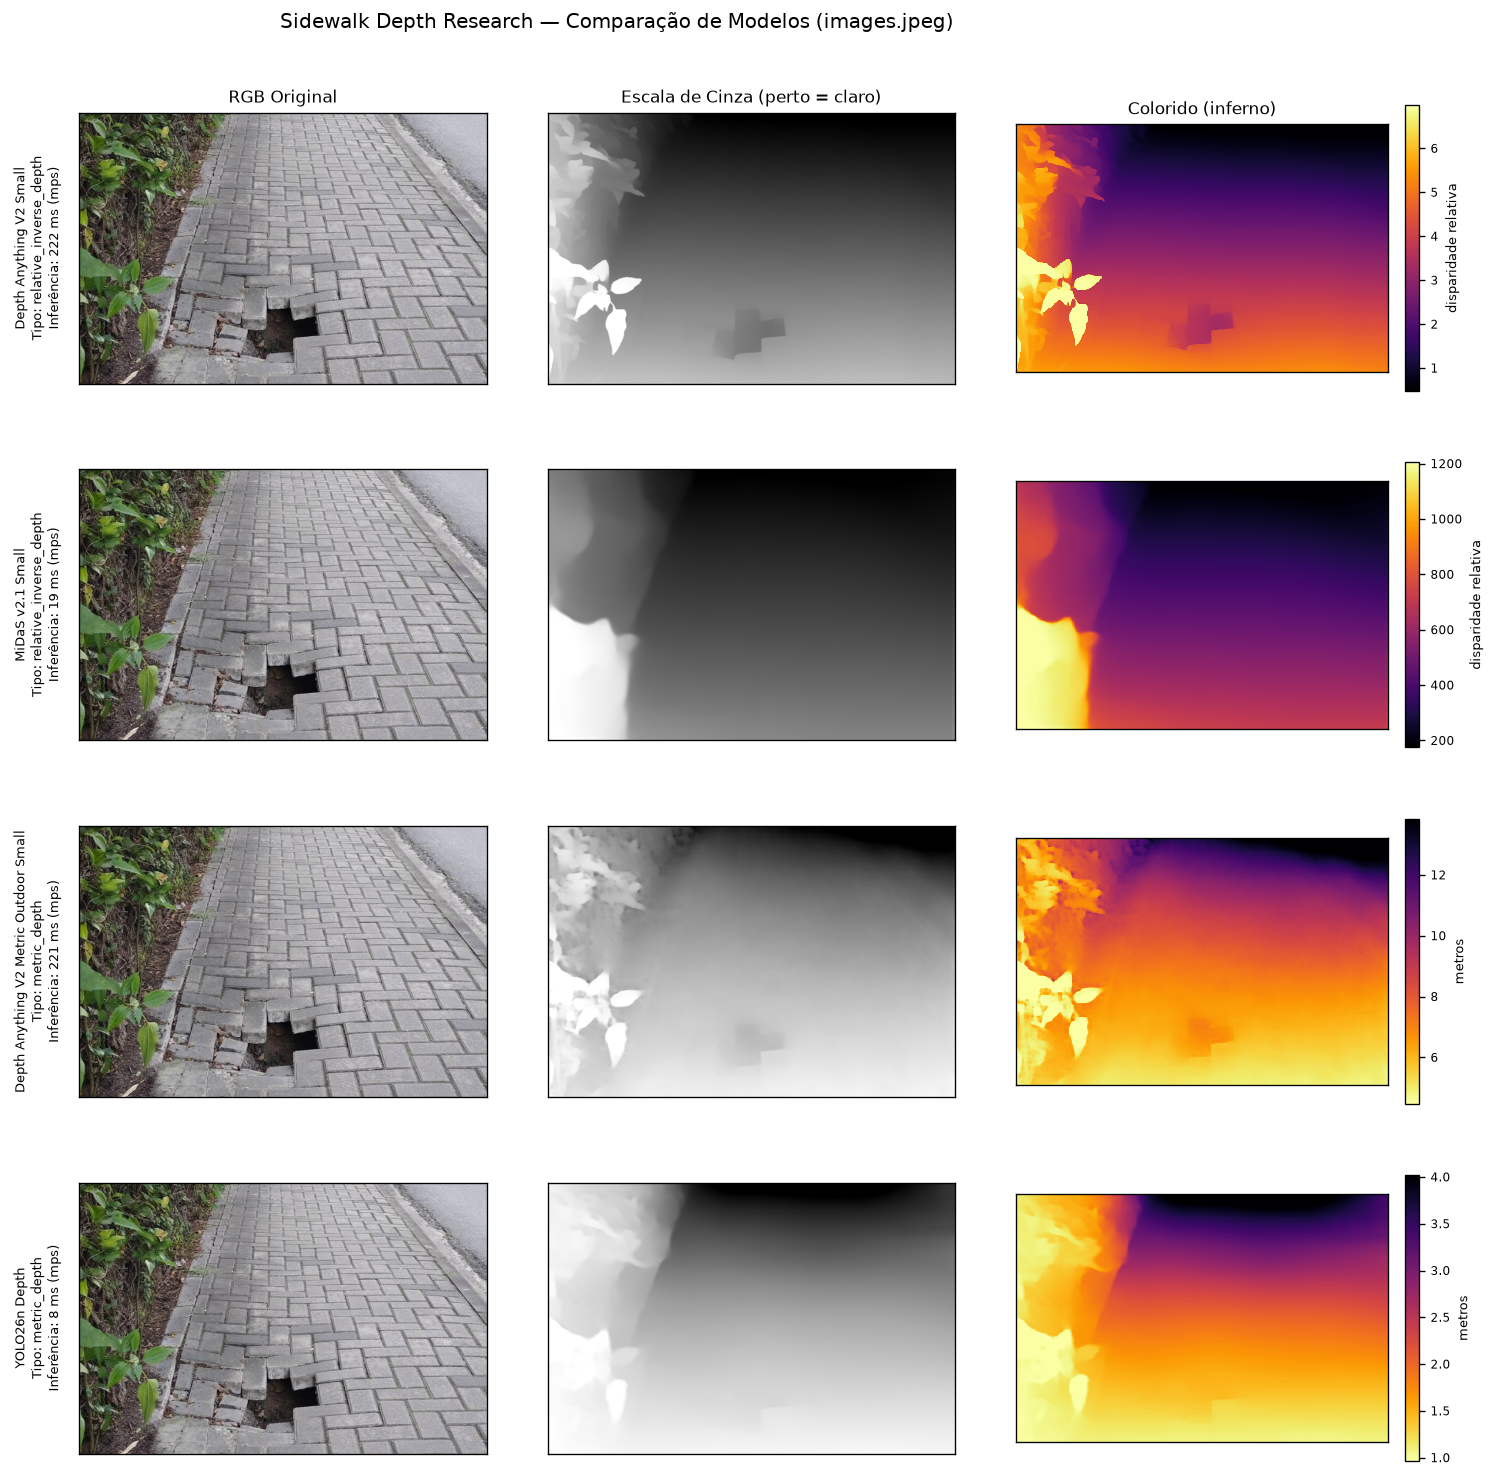

In [58]:
fig = plot_comparison(
    image_rgb=image.rgb,
    results=results,
    title=f"Sidewalk Depth Research — Comparação de Modelos ({image.name})",
    panel_width=4.5,
)
plt.show()

## 4. Tabela Resumo dos Experimentos

Estatísticas descritivas das saídas brutas e métricas de desempenho em tempo de execução.

In [59]:
rows = []
for r in results:
    stats = r.stats()
    rows.append({
        "Modelo": r.model_name,
        "Natureza da Saída": r.output_type.value,
        "Unidade": r.units or "adimensional",
        "Tempo Inferência (ms)": round(r.inference_time_s * 1000, 1),
        "Tempo Total (ms)": round(r.total_time_s * 1000, 1),
        "Tensor Entrada": "x".join(map(str, r.model_input_shape)),
        "Resolução Saída": f"{r.output_shape[1]}x{r.output_shape[0]}",
        "Mín": round(stats["min"], 3),
        "Máx": round(stats["max"], 3),
        "Mediana": round(stats["median"], 3),
        "Device": r.device,
    })

df_summary = pd.DataFrame(rows)
df_summary

,Modelo,Natureza da Saída,Unidade,Tempo Inferência (ms),Tempo Total (ms),Tensor Entrada,Resolução Saída,Mín,Máx,Mediana,Device
0,Depth Anything V2 Small,relative_inverse_depth,adimensional,222.5,233.0,1x3x518x784,784x518,0.289,9.314,3.317,mps
1,MiDaS v2.1 Small,relative_inverse_depth,adimensional,19.4,22.5,1x3x160x256,256x160,148.890,1269.835,506.338,mps
2,Depth Anything V2 Metric Outdoor Small,metric_depth,meters,221.3,233.1,1x3x518x784,784x518,3.695,23.853,7.189,mps
3,YOLO26n Depth,metric_depth,meters,8.3,9.4,1x3x768x768,192x192,0.716,4.405,1.723,mps


## 5. Persistência dos Resultados

Para cada execução, armazenamos:
- **`outputs/depth_maps/<imagem>/<modelo>.npz`**: Dados brutos (`depth` interpolado e `raw_output` da rede);
- **`outputs/depth_maps/<imagem>/<modelo>.json`**: Metadados completos e hash da imagem;
- **`outputs/depth_maps/<imagem>/<modelo>_{gray,color}.png`**: Visualizações ilustrativas;
- **`outputs/comparisons/comparison_<imagem>.png`**: Painel comparativo consolidado;
- **`outputs/reports/inference_log.csv`**: Histórico cumulativo dos experimentos.

In [60]:
out_comparisons_dir = get_path("comparisons_dir", create=True)

for r in results:
    npz_path = save_depth_result(r, image.path)
    vis_paths = save_depth_visualizations(r, npz_path.parent)
    append_inference_log(r, image.path, artifact=npz_path)
    print(f"Salvo [{r.model_key}]:")
    print(f"  • Dados brutos:    {npz_path.relative_to(PROJECT_ROOT)}")
    print(f"  • Visualização:    {vis_paths['color'].relative_to(PROJECT_ROOT)}")

# Salva a figura comparativa
comp_path = out_comparisons_dir / f"comparison_{image.path.stem}.png"
save_figure(fig, comp_path)
print(f"\n✓ Painel comparativo salvo em: {comp_path.relative_to(PROJECT_ROOT)}")
print(f"✓ Log geral atualizado em: outputs/reports/inference_log.csv")

Salvo [depth_anything_v2_small]:
  • Dados brutos:    outputs/depth_maps/images/depth_anything_v2_small.npz
  • Visualização:    outputs/depth_maps/images/depth_anything_v2_small_color.png
Salvo [midas_v21_small]:
  • Dados brutos:    outputs/depth_maps/images/midas_v21_small.npz
  • Visualização:    outputs/depth_maps/images/midas_v21_small_color.png
Salvo [depth_anything_v2_metric_outdoor_small]:
  • Dados brutos:    outputs/depth_maps/images/depth_anything_v2_metric_outdoor_small.npz
  • Visualização:    outputs/depth_maps/images/depth_anything_v2_metric_outdoor_small_color.png
Salvo [yolo26n_depth]:
  • Dados brutos:    outputs/depth_maps/images/yolo26n_depth.npz
  • Visualização:    outputs/depth_maps/images/yolo26n_depth_color.png

✓ Painel comparativo salvo em: outputs/comparisons/comparison_images.png
✓ Log geral atualizado em: outputs/reports/inference_log.csv
